# Code-Mixed Offensive Language Detection — EDA, Baselines & Leakage-Safe Evaluation

This notebook inspects the official **train / dev / test** splits for the Bangla-English-Hindi code-mixed offensive-language dataset, then compares raw text with conservative multilingual-safe preprocessing.

### Expected official split sizes (verified dynamically below)

| Split | Expected rows | Label counts reported by dataset README |
|---|---:|---|
| Train | 60,000 | `NOT`: 40,018 · `OFF`: 19,982 |
| Dev | 20,000 | `NOT`: 13,339 · `OFF`: 6,661 |
| Test | 20,000 | `NOT`: 13,340 · `OFF`: 6,660 |
| **Total** | **100,000** | **Class ratio approximately 2:1** |

The notebook does not blindly trust these counts: it loads the files available in the Kaggle input directory and prints the actual dimensions and label distributions. If `dev.csv` is not mounted, the notebook continues with train/test and clearly reports that dev is unavailable.

### Main data-quality concerns

1. `id` is not a unique row identifier; variants of the same underlying source can have the same ID.
2. IDs and text may overlap across splits. The overlap tables below measure this directly for the local files.
3. `user` is strongly associated with the target in this dataset, creating identity-leakage risk if used as a model feature.
4. Many rows have missing metadata but still contain text; do not drop them solely because metadata is missing.
5. Text is multilingual/code-mixed (Bangla, English, Hindi/Devanagari). Do not remove non-ASCII characters or apply English-only stemming/stopwords by default.

### Evaluation protocol

- **Grouped 5-fold CV on train:** keeps each known user's rows within one fold, with ID/text fallback for missing user metadata.
- **Official dev evaluation:** fits on train and evaluates on `dev.csv`, if present.
- **Test:** reserve for final reporting; do not repeatedly tune decisions against test-label metrics.

The notebook includes reference baseline values supplied in the project notes, but clearly labels those values as reference-only until reproduced under the exact same split protocol.

**Dataset source note:** the public dataset description reports train/dev/test as 60k/20k/20k with `NOT`/`OFF` counts listed above. Always use the dynamic local tables as the source of truth for your downloaded files.

In [1]:

# ============================================================
# 1. SETUP
# ============================================================
import re
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

print("Ready.")


Ready.


In [2]:
# ============================================================
# 2. AUTO-DISCOVER TRAIN / DEV / TEST CSV FILES
# Works in Kaggle. dev.csv is optional; when found it is included.
# ============================================================
search_roots = [
    Path("/kaggle/input"),
    Path("."),
    Path("/mnt/data"),
    Path("/content"),
]

# Explicit path provided in the project notes (if mounted as written).
EXPECTED_DEV_PATH = Path(
    "/kaggle/input/datasets/mdnishatraihan/code-mixed-offensive-bangla-english-hindi/dev.csv"
)

def discover_csv(pattern, preferred_names=None, required=True):
    candidates = []
    preferred_names = preferred_names or []

    for root in search_roots:
        if not root.exists():
            continue
        if str(root) == "/kaggle/input":
            candidates.extend(root.rglob(pattern))
        else:
            candidates.extend(root.glob(pattern))

    candidates = list(dict.fromkeys(candidates))
    for pref in preferred_names:
        for p in candidates:
            if p.name.lower() == pref.lower():
                return p

    if candidates:
        return sorted(candidates, key=lambda p: (len(p.parts), str(p)))[0]

    if required:
        raise FileNotFoundError(
            f"Could not find {pattern}. Check that the CSV is attached or mounted under /kaggle/input."
        )
    return None

TRAIN_PATH = discover_csv(
    "train*.csv", preferred_names=["train(2).csv", "train.csv"], required=True
)
TEST_PATH = discover_csv(
    "test*.csv", preferred_names=["test(2).csv", "test.csv"], required=True
)

if EXPECTED_DEV_PATH.exists():
    DEV_PATH = EXPECTED_DEV_PATH
else:
    DEV_PATH = discover_csv("dev.csv", preferred_names=["dev.csv"], required=False)

print("TRAIN:", TRAIN_PATH)
print("DEV  :", DEV_PATH if DEV_PATH else "NOT FOUND — official dev evaluation will be skipped")
print("TEST :", TEST_PATH)

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
dev = pd.read_csv(DEV_PATH) if DEV_PATH is not None else None

print("\\nLoaded split dimensions")
print("Train:", train.shape)
print("Dev  :", dev.shape if dev is not None else "not loaded")
print("Test :", test.shape)
print("Total loaded rows:", len(train) + (len(dev) if dev is not None else 0) + len(test))
display(train.head(3))
if dev is not None:
    display(dev.head(3))

TRAIN: /kaggle/input/datasets/mdnishatraihan/code-mixed-offensive-bangla-english-hindi/train.csv
TEST : /kaggle/input/datasets/mdnishatraihan/code-mixed-offensive-bangla-english-hindi/test.csv

Train shape: (60000, 6)
Test shape : (20000, 6)


,id,text,user,state,time,label
0,39056.0,@USER I’m একজন অসুস্থ भाड़ में जाओ मैं পছন্দ করতে দ্রুত চোদাচুদি,steve11,CT,9:25:20,OFF
1,72660.0,@USER @USER আপনি মিস করেছেন seeing Pruitt chewing butt यहां तक শেষ সে সব व्यवसाय। मुझे इससे प्यार है,jennifer55,CT,7:14:19,OFF
2,86747.0,.@USER says she’s में एक रिपब्लिकन এর ছাঁচ लिंकन और रीगन। বন্দুক নিয়ন্ত্রণ সমর্থন করে।,ann87,FL,4:03:26,NOT



## 3. Dataset structure

The current schema is:

- `id` — source/sample identifier, **not a safe modeling feature**
- `text` — the main NLP input
- `user` — user metadata; potentially very leaky
- `state` — categorical metadata
- `time` — timestamp-like metadata
- `label` — binary target (`OFF` / `NOT`)

The first modeling track in this notebook intentionally excludes `id`, `user`, `state`, and `time`.


In [3]:

# ============================================================
# 4. BASIC SCHEMA + DATA QUALITY AUDIT
# ============================================================
def quality_report(df, name):
    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
        "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
    })
    report["duplicate_values_%"] = (
        (1 - report["n_unique"] / len(df)) * 100
    ).round(2)

    print(f"===== {name.upper()} =====")
    print("Shape:", df.shape)
    print("Duplicate complete rows:", int(df.duplicated().sum()))
    display(report)
    display(df.describe(include="all").T)

quality_report(train, "train")
if dev is not None:
    quality_report(dev, "dev")
quality_report(test, "test")


===== TRAIN =====
Shape: (60000, 6)
Duplicate complete rows: 456


,dtype,missing,missing_%,n_unique,duplicate_values_%
id,float64,12402,20.67,13187,78.02
text,object,0,0.00,58765,2.06
user,object,12402,20.67,11,99.98
state,object,12402,20.67,5,99.99
time,object,12402,20.67,12226,79.62
label,object,0,0.00,2,100.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,47598.0,NaN,NaN,NaN,54771.705618,26065.675983,10006.0,32147.0,54632.5,77527.0,99986.0
text,60000,58765,#NAME?,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user,47598,11,sam42,9073,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,47598,5,DE,9660,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,47598,12226,14:22:42,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,60000,2,NOT,40018,NaN,NaN,NaN,NaN,NaN,NaN,NaN


===== TEST =====
Shape: (20000, 6)
Duplicate complete rows: 44


,dtype,missing,missing_%,n_unique,duplicate_values_%
id,float64,4072,20.36,9829,50.86
text,object,0,0.00,19873,0.63
user,object,4072,20.36,11,99.94
state,object,4072,20.36,5,99.98
time,object,4072,20.36,9293,53.54
label,object,0,0.00,2,99.99


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,15928.0,NaN,NaN,NaN,54891.309329,26078.008646,10006.0,32324.25,54939.0,77763.75,99981.0
text,20000,19873,#NAME?,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user,15928,11,matt31,3103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,15928,5,DE,3259,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,15928,9293,1:29:01,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,20000,2,NOT,13340,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,percent
label,,
NOT,40018,66.7
OFF,19982,33.3


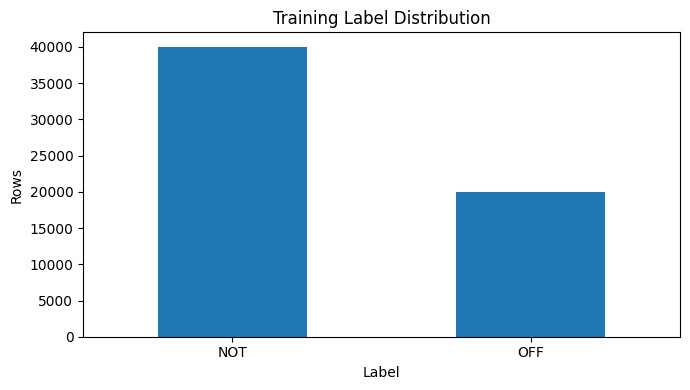

In [4]:

# ============================================================
# 5. TARGET AUDIT
# ============================================================
assert "label" in train.columns, "Expected a 'label' column in train."

label_counts = train["label"].value_counts(dropna=False)
label_pct = train["label"].value_counts(normalize=True, dropna=False).mul(100).round(2)

target_summary = pd.DataFrame({
    "count": label_counts,
    "percent": label_pct
})

display(target_summary)

fig, ax = plt.subplots(figsize=(7, 4))
target_summary["count"].plot(kind="bar", ax=ax)
ax.set_title("Training Label Distribution")
ax.set_xlabel("Label")
ax.set_ylabel("Rows")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()



Train


,missing_count,missing_percent
id,12402,20.67
user,12402,20.67
time,12402,20.67
state,12402,20.67
text,0,0.00
label,0,0.00


Rows with any metadata missing: 12402
Label distribution among those rows:


label
NOT    66.58
OFF    33.42
Name: proportion, dtype: float64


Test


,missing_count,missing_percent
id,4072,20.36
user,4072,20.36
time,4072,20.36
state,4072,20.36
text,0,0.00
label,0,0.00


Rows with any metadata missing: 4072
Label distribution among those rows:


label
NOT    65.86
OFF    34.14
Name: proportion, dtype: float64

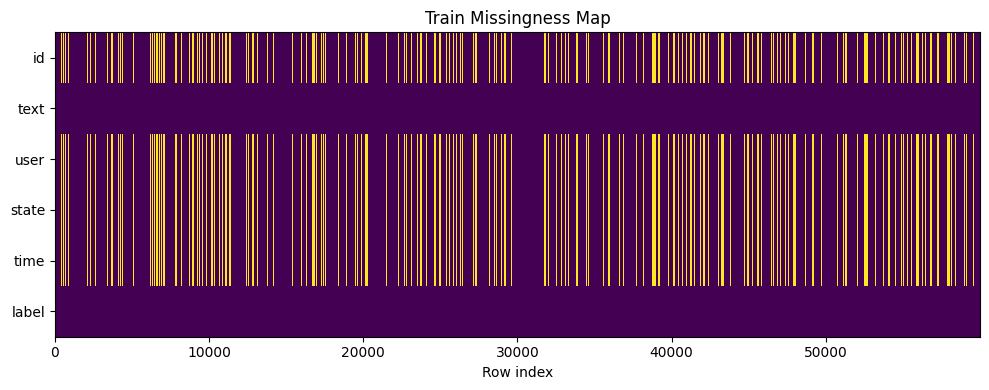

In [5]:

# ============================================================
# 6. MISSINGNESS ANALYSIS
# ============================================================
split_frames = [("Train", train)] + ([ ("Dev", dev) ] if dev is not None else []) + [("Test", test)]
for name, df in split_frames:
    miss = df.isna().sum().sort_values(ascending=False)
    miss_pct = df.isna().mean().mul(100).sort_values(ascending=False)

    print(f"\n{name}")
    display(pd.DataFrame({
        "missing_count": miss,
        "missing_percent": miss_pct.round(2)
    }))

    if "label" in df.columns:
        meta_cols = [c for c in ["id", "user", "state", "time"] if c in df.columns]
        any_meta_missing = df[meta_cols].isna().any(axis=1)
        print("Rows with any metadata missing:", int(any_meta_missing.sum()))
        print("Label distribution among those rows:")
        display(df.loc[any_meta_missing, "label"].value_counts(normalize=True).mul(100).round(2))

# Visual missingness matrix without extra dependencies
fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(train.isna().T, aspect="auto", interpolation="nearest")
ax.set_yticks(range(train.shape[1]))
ax.set_yticklabels(train.columns)
ax.set_xlabel("Row index")
ax.set_title("Train Missingness Map")
plt.tight_layout()
plt.show()



### Missing-value decision

Do **not** delete the 20% of rows with missing metadata, because their `text` is still present.

For the text-only model:
- `text` → keep
- `label` → keep
- `id/user/state/time` → audit only, not model inputs

If metadata is later used in an ablation study, missing categories should be handled explicitly (`MISSING`) rather than dropping rows.


In [6]:

# ============================================================
# 7. TEXT QUALITY + DUPLICATE AUDIT
# ============================================================
def normalize_for_audit(text):
    text = str(text)
    text = text.replace("\u200b", " ")
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

train["text_audit"] = train["text"].map(normalize_for_audit)
test["text_audit"] = test["text"].map(normalize_for_audit)
if dev is not None:
    dev["text_audit"] = dev["text"].map(normalize_for_audit)

split_frames = [("Train", train)] + ([ ("Dev", dev) ] if dev is not None else []) + [("Test", test)]
for name, df in split_frames:
    text = df["text"].fillna("").astype(str)
    stats = pd.Series({
        "empty_text_rows": int(text.str.strip().eq("").sum()),
        "raw_duplicate_text_rows": int(text.duplicated().sum()),
        "normalized_duplicate_text_rows": int(df["text_audit"].duplicated().sum()),
        "unique_raw_texts": int(text.nunique()),
        "unique_normalized_texts": int(df["text_audit"].nunique()),
        "mean_chars": text.str.len().mean(),
        "median_chars": text.str.len().median(),
        "max_chars": text.str.len().max(),
        "mean_words": text.str.split().str.len().mean(),
        "median_words": text.str.split().str.len().median(),
        "max_words": text.str.split().str.len().max(),
    })
    print(f"\n{name} text audit")
    display(stats.to_frame("value"))

# Duplicate-text label conflicts
dup_label_nunique = (
    train.groupby("text_audit", dropna=False)["label"].nunique()
)
conflict_groups = dup_label_nunique[dup_label_nunique > 1]

print("Conflicting normalized-text groups in train:", len(conflict_groups))

if len(conflict_groups):
    conflict_examples = (
        train[train["text_audit"].isin(conflict_groups.index)]
        .sort_values("text_audit")
        [["text", "label"]]
        .drop_duplicates()
        .head(20)
    )
    display(conflict_examples)



Train text audit


,value
empty_text_rows,0.000000
raw_duplicate_text_rows,1235.000000
normalized_duplicate_text_rows,1257.000000
unique_raw_texts,58765.000000
unique_normalized_texts,58743.000000
mean_chars,126.706450
median_chars,103.000000
max_chars,596.000000
mean_words,22.983367
median_words,19.000000



Test text audit


,value
empty_text_rows,0.00000
raw_duplicate_text_rows,127.00000
normalized_duplicate_text_rows,130.00000
unique_raw_texts,19873.00000
unique_normalized_texts,19870.00000
mean_chars,127.52105
median_chars,104.00000
max_chars,587.00000
mean_words,23.16405
median_words,19.00000


Conflicting normalized-text groups in train: 9


,text,label
38864,@USER @USER हाँ তিনি হয়,OFF
34902,@USER @USER हाँ তিনি হয়,NOT
26144,@USER FAKE समाचार,NOT
1129,@USER Fake समाचार,OFF
31912,@USER Fake খবর,NOT
40183,@USER Fake খবর,OFF
1706,@USER sexy,OFF
33723,@USER Sexy,NOT
25679,@USER कामुक,NOT
16705,@USER कामुक,OFF


In [7]:

# ============================================================
# 8. ID / SOURCE AUGMENTATION AUDIT
# ============================================================
id_stats = (
    train.dropna(subset=["id"])
    .groupby("id")
    .agg(
        rows=("label", "size"),
        unique_texts=("text_audit", "nunique"),
        unique_users=("user", "nunique"),
        unique_labels=("label", "nunique"),
    )
    .sort_values("rows", ascending=False)
)

print("Repeated train IDs:", int((id_stats["rows"] > 1).sum()))
print("IDs with >1 text variant:", int((id_stats["unique_texts"] > 1).sum()))
print("IDs with conflicting labels:", int((id_stats["unique_labels"] > 1).sum()))

display(id_stats.head(15))

# Train/test ID overlap
train_ids = set(train["id"].dropna())
test_ids = set(test["id"].dropna())
id_overlap = train_ids & test_ids

print("\nDistinct train IDs:", len(train_ids))
print("Distinct test IDs :", len(test_ids))
print("Train-test shared IDs:", len(id_overlap))


Repeated train IDs: 12735
IDs with >1 text variant: 12717
IDs with conflicting labels: 0


,rows,unique_texts,unique_users,unique_labels
id,,,,
28696.0,6,6,1,1
67667.0,6,6,1,1
96821.0,6,6,1,1
12887.0,6,6,1,1
69898.0,6,6,1,1
73659.0,6,6,1,1
50831.0,6,6,1,1
40197.0,6,5,1,1
50299.0,6,6,1,1



Distinct train IDs: 13187
Distinct test IDs : 9829
Train-test shared IDs: 9777



## Why this matters

The repeated-ID pattern strongly suggests that multiple rows are variants of the same underlying source item.

A random row split can put one variant in training and another variant in validation. The model then appears to generalize, while it is partly memorizing source-specific wording.

Therefore, **validation must be grouped by source ID**.

Because some rows have missing IDs, this notebook also links rows by normalized text. The resulting groups are connected components of:

- same source `id`, OR
- same normalized text

This is stricter than ordinary `GroupShuffleSplit` by ID alone.


In [8]:

# ============================================================
# 9. USER / STATE / TIME LEAKAGE AUDIT
# ============================================================
for col in ["user", "state"]:
    if col not in train.columns:
        continue

    print(f"\n===== {col.upper()} vs LABEL =====")
    counts = pd.crosstab(train[col].fillna("MISSING"), train["label"])
    rates = pd.crosstab(
        train[col].fillna("MISSING"),
        train["label"],
        normalize="index"
    ).round(3)
    display(counts)
    display(rates)

# Time extraction for EDA only
if "time" in train.columns:
    tmp = pd.to_datetime(train["time"], format="%H:%M:%S", errors="coerce")
    train["hour_eda"] = tmp.dt.hour

    print("Label distribution by hour (EDA only):")
    display(
        pd.crosstab(
            train["hour_eda"],
            train["label"],
            normalize="index"
        ).round(3)
    )

print("\nRecommended research setup: do not use user/state/time as primary NLP features.")



===== USER vs LABEL =====


label,NOT,OFF
user,,
MISSING,8257,4145
ann87,6592,2399
bob747,0,1897
danTHEman11,0,81
george45,6193,2534
jennifer55,5975,2449
jimbo99,0,202
matt31,6428,2625
sam42,6573,2500


label,NOT,OFF
user,,
MISSING,0.666,0.334
ann87,0.733,0.267
bob747,0.000,1.000
danTHEman11,0.000,1.000
george45,0.710,0.290
jennifer55,0.709,0.291
jimbo99,0.000,1.000
matt31,0.710,0.290
sam42,0.724,0.276



===== STATE vs LABEL =====


label,NOT,OFF
state,,
CT,6328,3216
DE,6457,3203
FL,6252,3242
MISSING,8257,4145
NY,6309,3185
VA,6415,2991


label,NOT,OFF
state,,
CT,0.663,0.337
DE,0.668,0.332
FL,0.659,0.341
MISSING,0.666,0.334
NY,0.665,0.335
VA,0.682,0.318


Label distribution by hour (EDA only):


label,NOT,OFF
hour_eda,,
0.0,0.697,0.303
1.0,0.690,0.310
2.0,0.667,0.333
3.0,0.688,0.312
4.0,0.669,0.331
5.0,0.665,0.335
6.0,0.654,0.346
7.0,0.653,0.347
8.0,0.691,0.309



Recommended research setup: do not use user/state/time as primary NLP features.


,feature,rows,percent
0,Latin,59987,99.98
1,Bengali,56190,93.65
2,Devanagari,56480,94.13
3,Mentions (@USER),54403,90.67
4,Hashtags,8731,14.55
5,URL placeholder,8604,14.34


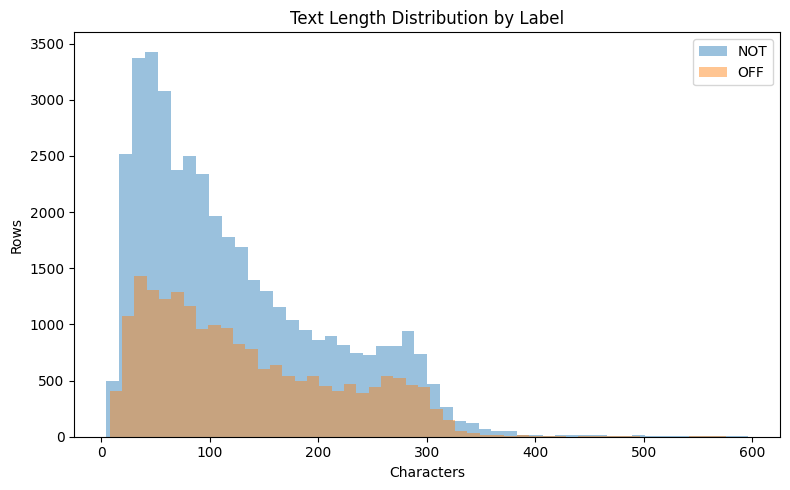

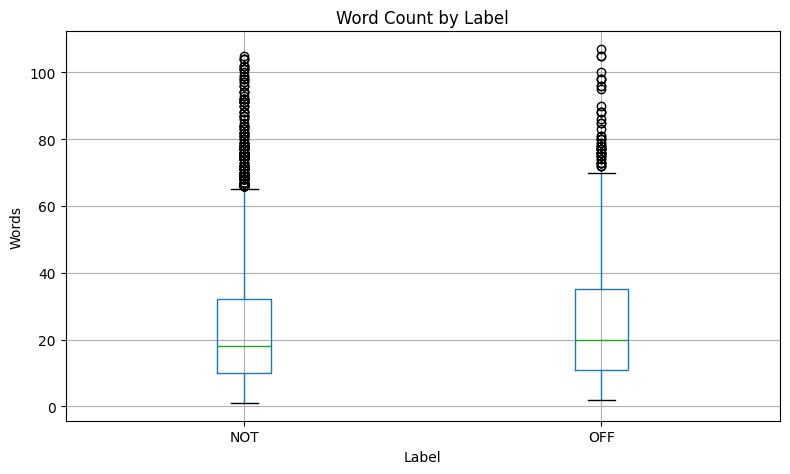

In [9]:

# ============================================================
# 10. MULTILINGUAL / CODE-MIXED TEXT AUDIT
# ============================================================
text = train["text"].astype(str)

patterns = {
    "Latin": r"[A-Za-z]",
    "Bengali": r"[\u0980-\u09FF]",
    "Devanagari": r"[\u0900-\u097F]",
    "Mentions (@USER)": r"@USER",
    "Hashtags": r"#[\w_]+",
    "URL placeholder": r"\b(?:URL|यूआरएल)\b",
}

script_stats = []
for name, pattern in patterns.items():
    count = int(text.str.contains(pattern, regex=True, na=False).sum())
    script_stats.append({
        "feature": name,
        "rows": count,
        "percent": round(count / len(train) * 100, 2)
    })

display(pd.DataFrame(script_stats))

length_df = pd.DataFrame({
    "chars": text.str.len(),
    "words": text.str.split().str.len(),
    "label": train["label"]
})

fig, ax = plt.subplots(figsize=(8, 5))
for label in sorted(length_df["label"].unique()):
    vals = length_df.loc[length_df["label"] == label, "chars"]
    ax.hist(vals, bins=50, alpha=0.45, label=label)
ax.set_title("Text Length Distribution by Label")
ax.set_xlabel("Characters")
ax.set_ylabel("Rows")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
length_df.boxplot(column="words", by="label", ax=ax)
ax.set_title("Word Count by Label")
ax.set_xlabel("Label")
ax.set_ylabel("Words")
plt.suptitle("")
plt.tight_layout()
plt.show()



### Language-aware preprocessing strategy

This dataset should **not** be processed like ordinary English-only sentiment data.

Avoid:
- English stopword-only pipelines
- stemming everything to English roots
- deleting all punctuation
- stripping non-ASCII characters
- translating everything to English as a first preprocessing step

Prefer:
- Unicode normalization
- removal of zero-width/control artifacts
- canonical placeholders for mentions and URLs
- whitespace normalization
- keeping Bengali, Hindi/Devanagari and English code-mixing
- preserving hashtags and emojis unless a specific experiment proves they are harmful


In [10]:

# ============================================================
# 11. MODERN, MINIMAL, MULTILINGUAL-SAFE TEXT PREPROCESSING
# ============================================================
ZERO_WIDTH_RE = re.compile(r"[\u200B-\u200D\uFEFF]")
URL_RE = re.compile(
    r"(https?://\S+|www\.\S+|\bURL\b|\bयूआरएल\b)",
    flags=re.IGNORECASE
)
MENTION_RE = re.compile(r"@\w+|@USER", flags=re.IGNORECASE)
SPACE_RE = re.compile(r"\s+")

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Unicode compatibility normalization
    import unicodedata
    text = unicodedata.normalize("NFKC", text)

    # Remove invisible formatting characters
    text = ZERO_WIDTH_RE.sub(" ", text)

    # Keep semantic placeholders instead of deleting the information
    text = URL_RE.sub(" URL ", text)
    text = MENTION_RE.sub(" USER ", text)

    # Lowercasing is safe for TF-IDF because the task is not case-sensitive,
    # while Unicode characters are preserved.
    text = text.lower()

    # Normalize whitespace only
    text = SPACE_RE.sub(" ", text).strip()
    return text

train["text_clean"] = train["text"].map(clean_text)
test["text_clean"] = test["text"].map(clean_text)

display(
    train[["text", "text_clean", "label"]].sample(
        10, random_state=RANDOM_STATE
    )
)


,text,text_clean,label
12628,@USER @USER @USER @USER @USER You एक अच्छे डांसर और टैलेंटेड हैं অঙ্কন মধ্যে আমার আঙ্গুলের মত कि जब मैं CNCO को वोट देता हूँ 😂 #PremiosHeat2018 @USER #LatinGRAMMYCNCO #CNCOnEll...,user user user user user you एक अच्छे डांसर और टैलेंटेड हैं অঙ্কন মধ্যে আমার আঙ্গুলের মত कि जब मैं cnco को वोट देता हूँ 😂 #premiosheat2018 user #latingrammycnco #cnconellen use...,NOT
37730,आसमान भरना - रसायन এবং ফ্রিকোয়েন্সি #IDoNotConsent #WeDoNotConsent #OpEvidence #opstopchemtrails #Chemtrails #SkyBastard #Geoengineering #climatechange #SRM #Cloudseeding #Eve...,आसमान भरना - रसायन এবং ফ্রিকোয়েন্সি #idonotconsent #wedonotconsent #opevidence #opstopchemtrails #chemtrails #skybastard #geoengineering #climatechange #srm #cloudseeding #eve...,NOT
39991,@USER সিএনএন খারাপ। A true enemy of लोग। मैं नहीं कर सकता বিশ্বাস করুন মানুষ আছে who still take them seriously.,user সিএনএন খারাপ। a true enemy of लोग। मैं नहीं कर सकता বিশ্বাস করুন মানুষ আছে who still take them seriously.,OFF
8525,People leaving racist comments on my posts will be तुरंत ब्लॉक कर दिया। इसे पोस्ट करने वाले कम फॉलोअर अकाउंट हैं বাজে কথা এবং আমি মনে করি তারা তৈরি করার চেষ্টা করছে #MAGA look ...,people leaving racist comments on my posts will be तुरंत ब्लॉक कर दिया। इसे पोस्ट करने वाले कम फॉलोअर अकाउंट हैं বাজে কথা এবং আমি মনে করি তারা তৈরি করার চেষ্টা করছে #maga look ...,OFF
8279,@USER @USER @USER What बहुतों को जगाया है এই দেশে নারী অ্যাসিনিন শেষ की शीर्ष मूर्खता liberals today!!,user user user what बहुतों को जगाया है এই দেশে নারী অ্যাসিনিন শেষ की शीर्ष मूर्खता liberals today!!,OFF
51012,@USER @USER She is as বোবা হিসাবে she looks,user user she is as বোবা হিসাবে she looks,OFF
14871,@USER आप মিথ্যা হয় Stick with তথ্য We pay more than এখনই.,user आप মিথ্যা হয় stick with তথ্য we pay more than এখনই.,NOT
15127,@USER jimin-ssi i আশা করি আপনি জানেন तुम यह हो देवदूत। मुझे पसंद है you so much. आप हमेशा से আশ্চর্যজনক,user jimin-ssi i আশা করি আপনি জানেন तुम यह हो देवदूत। मुझे पसंद है you so much. आप हमेशा से আশ্চর্যজনক,NOT
9366,"@USER @USER मैं एल्क पर विश्वास नहीं करता রাইফেল ধরতে পারলেও could purchase one. Although you would probably समझदार बंदूक नियंत्रण कानून चाहते हैं"" এলক নিজেকে রক্ষা করতে কিনতে ...","user user मैं एल्क पर विश्वास नहीं करता রাইফেল ধরতে পারলেও could purchase one. although you would probably समझदार बंदूक नियंत्रण कानून चाहते हैं"" এলক নিজেকে রক্ষা করতে কিনতে পা...",NOT
33322,@USER भूरा like you,user भूरा like you,NOT


In [11]:

# ============================================================
# 12. EXACT / NORMALIZED DUPLICATE REPORT AFTER CLEANING
# ============================================================
for name, df in [("Train", train), ("Test", test)]:
    ndup = df["text_clean"].duplicated(keep=False)
    print(
        f"{name}: {ndup.sum()} rows belong to a repeated cleaned-text group."
    )

# Small conflict audit
clean_conflicts = (
    train.groupby("text_clean")["label"].nunique()
)
clean_conflicts = clean_conflicts[clean_conflicts > 1]

print(
    "Cleaned-text groups with conflicting labels:",
    len(clean_conflicts)
)


Train: 2441 rows belong to a repeated cleaned-text group.
Test: 261 rows belong to a repeated cleaned-text group.
Cleaned-text groups with conflicting labels: 9


In [12]:

# ============================================================
# 13. LEAKAGE-SAFE CONNECTED COMPONENT GROUPING
#
# Connect rows when:
#   A) they share the same non-null ID, OR
#   B) they share the same cleaned text.
#
# This prevents both source-level augmentation leakage
# and exact-text leakage between train/validation.
# ============================================================
def connected_components_from_keys(df, id_col="id", text_col="text_clean"):
    n = len(df)
    parent = np.arange(n)
    size = np.ones(n, dtype=np.int32)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra == rb:
            return
        if size[ra] < size[rb]:
            ra, rb = rb, ra
        parent[rb] = ra
        size[ra] += size[rb]

    # Helper: union all rows sharing a key
    for key_series, valid_mask in [
        (df[id_col], df[id_col].notna()),
        (df[text_col], df[text_col].notna()),
    ]:
        key_to_first = {}
        for idx, key in key_series.items():
            if not valid_mask.loc[idx]:
                continue
            key_str = str(key)
            if key_str in key_to_first:
                union(key_to_first[key_str], idx)
            else:
                key_to_first[key_str] = idx

    roots = np.array([find(i) for i in range(n)])
    _, group_codes = np.unique(roots, return_inverse=True)
    return group_codes

train["source_group"] = connected_components_from_keys(train)

print("Rows:", len(train))
print("Leakage-safe groups:", train["source_group"].nunique())

# Sanity check: no overlap after grouped split
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)
idx_train, idx_val = next(
    gss.split(
        train,
        train["label"],
        groups=train["source_group"]
    )
)

print("Model train rows:", len(idx_train))
print("Validation rows  :", len(idx_val))
print(
    "Group overlap:",
    len(
        set(train.iloc[idx_train]["source_group"])
        & set(train.iloc[idx_val]["source_group"])
    )
)


Rows: 60000
Leakage-safe groups: 24694
Model train rows: 47999
Validation rows  : 12001
Group overlap: 0



## 14. Demonstrate why random validation is misleading

We intentionally run the same TF-IDF + LinearSVC baseline twice:

1. **Random row split** — useful only as a warning / sanity check.
2. **Leakage-safe grouped split** — the number to trust more for research.

Expected behavior on this dataset: the random split is substantially stronger because repeated IDs and text variants can cross the boundary.


In [13]:

# ============================================================
# 15. RANDOM SPLIT BASELINE (WARNING / DIAGNOSTIC ONLY)
# ============================================================
def make_text_model():
    features = FeatureUnion([
        (
            "word_tfidf",
            TfidfVectorizer(
                analyzer="word",
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.995,
                sublinear_tf=True,
                max_features=80000,
                strip_accents=None,
            ),
        ),
        (
            "char_tfidf",
            TfidfVectorizer(
                analyzer="char",
                ngram_range=(3, 5),
                min_df=2,
                sublinear_tf=True,
                max_features=80000,
            ),
        ),
    ])

    return FeatureUnion([
        ("tfidf", features)
    ])

# The nested FeatureUnion is intentionally explicit for notebook readability.
X_random = train["text_clean"]
y = train["label"]

r_train, r_val = train_test_split(
    np.arange(len(train)),
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

random_vectorizer = FeatureUnion([
    (
        "word",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.995,
            sublinear_tf=True,
            max_features=80000,
        ),
    ),
    (
        "char",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=80000,
        ),
    ),
])

Xtr = random_vectorizer.fit_transform(X_random.iloc[r_train])
Xva = random_vectorizer.transform(X_random.iloc[r_val])

random_clf = LinearSVC(
    C=2.0,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
random_clf.fit(Xtr, y.iloc[r_train])

pred_random = random_clf.predict(Xva)

random_metrics = {
    "accuracy": accuracy_score(y.iloc[r_val], pred_random),
    "macro_f1": f1_score(y.iloc[r_val], pred_random, average="macro"),
    "weighted_f1": f1_score(y.iloc[r_val], pred_random, average="weighted"),
}

display(pd.DataFrame([random_metrics]).round(4))
print(classification_report(y.iloc[r_val], pred_random, digits=4))


,accuracy,macro_f1,weighted_f1
0,0.8931,0.8786,0.8926


              precision    recall  f1-score   support

         NOT     0.9130    0.9282    0.9205      8004
         OFF     0.8512    0.8228    0.8367      3996

    accuracy                         0.8931     12000
   macro avg     0.8821    0.8755    0.8786     12000
weighted avg     0.8924    0.8931    0.8926     12000



In [14]:

# ============================================================
# 16. LEAKAGE-SAFE GROUPED BASELINE
# ============================================================
group_vectorizer = FeatureUnion([
    (
        "word",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.995,
            sublinear_tf=True,
            max_features=80000,
        ),
    ),
    (
        "char",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=80000,
        ),
    ),
])

Xtr = group_vectorizer.fit_transform(
    train.iloc[idx_train]["text_clean"]
)
Xva = group_vectorizer.transform(
    train.iloc[idx_val]["text_clean"]
)

group_clf = LinearSVC(
    C=2.0,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
group_clf.fit(Xtr, train.iloc[idx_train]["label"])

pred_group = group_clf.predict(Xva)

group_metrics = {
    "accuracy": accuracy_score(
        train.iloc[idx_val]["label"], pred_group
    ),
    "macro_f1": f1_score(
        train.iloc[idx_val]["label"],
        pred_group,
        average="macro"
    ),
    "weighted_f1": f1_score(
        train.iloc[idx_val]["label"],
        pred_group,
        average="weighted"
    ),
}

display(pd.DataFrame([group_metrics]).round(4))
print(classification_report(
    train.iloc[idx_val]["label"],
    pred_group,
    digits=4
))


,accuracy,macro_f1,weighted_f1
0,0.8026,0.7769,0.8007


              precision    recall  f1-score   support

         NOT     0.8370    0.8688    0.8526      7886
         OFF     0.7288    0.6758    0.7013      4115

    accuracy                         0.8026     12001
   macro avg     0.7829    0.7723    0.7769     12001
weighted avg     0.7999    0.8026    0.8007     12001



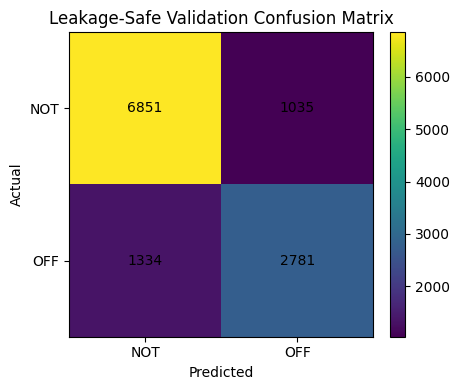

In [15]:

# ============================================================
# 17. CONFUSION MATRIX FOR THE TRUSTED VALIDATION
# ============================================================
cm = confusion_matrix(
    train.iloc[idx_val]["label"],
    pred_group,
    labels=["NOT", "OFF"]
)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Leakage-Safe Validation Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0, 1], ["NOT", "OFF"])
ax.set_yticks([0, 1], ["NOT", "OFF"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()



## 18. Final preprocessing + full-train model

For the final competition/modeling run:

- fit the text vectorizer on **train only**
- train on **all available train rows**
- never use test labels for fitting
- generate test predictions
- save a submission file
- optionally compare predictions with the provided test labels **only as an audit**, clearly marked as non-hidden evaluation

This gives a clean separation between model development and test-set supervision.


In [16]:

# ============================================================
# 19. TRAIN FINAL TEXT-ONLY MODEL ON ALL TRAIN ROWS
# ============================================================
final_vectorizer = FeatureUnion([
    (
        "word",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.995,
            sublinear_tf=True,
            max_features=100000,
        ),
    ),
    (
        "char",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=100000,
        ),
    ),
])

X_full = final_vectorizer.fit_transform(train["text_clean"])
X_test = final_vectorizer.transform(test["text_clean"])

final_clf = LinearSVC(
    C=2.0,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
final_clf.fit(X_full, train["label"])

test_pred = final_clf.predict(X_test)

print("Predictions generated:", len(test_pred))
print(pd.Series(test_pred).value_counts())


Predictions generated: 20000
NOT    13505
OFF     6495
Name: count, dtype: int64


In [17]:

# ============================================================
# 20. SAVE PROCESSED DATA + SUBMISSION
# ============================================================
processed_train = train.drop(
    columns=["text_audit", "hour_eda", "source_group"],
    errors="ignore"
).copy()

processed_test = test.drop(
    columns=["text_audit"],
    errors="ignore"
).copy()

processed_train.to_csv("train_processed.csv", index=False)
processed_test.to_csv("test_processed.csv", index=False)

# Generic submission format:
submission = pd.DataFrame({
    "id": test["id"],
    "label": test_pred,
})
submission.to_csv("submission.csv", index=False)

# Also save a complete prediction file for inspection.
test_predictions = test.copy()
test_predictions["predicted_label"] = test_pred
test_predictions.to_csv("test_predictions_full.csv", index=False)

print("Saved:")
for f in [
    "train_processed.csv",
    "test_processed.csv",
    "submission.csv",
    "test_predictions_full.csv",
]:
    print(" -", f)
display(submission.head(10))


Saved:
 - train_processed.csv
 - test_processed.csv
 - submission.csv
 - test_predictions_full.csv


,id,label
0,39013.0,NOT
1,66242.0,NOT
2,44298.0,OFF
3,NaN,NOT
4,49250.0,NOT
5,68239.0,NOT
6,35164.0,NOT
7,51312.0,NOT
8,78494.0,OFF
9,38349.0,NOT


In [18]:

# ============================================================
# 21. OPTIONAL: TEST LABEL AUDIT ONLY
#
# IMPORTANT:
# The uploaded test.csv contains a label column.
# Do NOT use it during training.
# This score is NOT a clean hidden-test estimate because
# train/test share IDs and some texts.
# ============================================================
if "label" in test.columns:
    audit_accuracy = accuracy_score(test["label"], test_pred)
    audit_macro_f1 = f1_score(test["label"], test_pred, average="macro")

    print("=== TEST LABEL AUDIT (NOT a hidden-test score) ===")
    print(f"Accuracy : {audit_accuracy:.4f}")
    print(f"Macro F1 : {audit_macro_f1:.4f}")
    print("\nClassification report:")
    print(classification_report(
        test["label"],
        test_pred,
        digits=4
    ))
else:
    print("No test label found. Good: test labels remain hidden.")


=== TEST LABEL AUDIT (NOT a hidden-test score) ===
Accuracy : 0.9181
Macro F1 : 0.9072

Classification report:
              precision    recall  f1-score   support

         NOT     0.9332    0.9448    0.9389     13340
         OFF     0.8865    0.8646    0.8754      6660

    accuracy                         0.9181     20000
   macro avg     0.9099    0.9047    0.9072     20000
weighted avg     0.9177    0.9181    0.9178     20000




# 22. Research recommendations

### Primary result to report
Use the **grouped validation result** as the main baseline, not the random-split score.

### Recommended model progression

**Baseline**
- Word TF-IDF (1–2 grams) + character TF-IDF (3–5 grams)
- LinearSVC

**Strong modern model**
- Fine-tune `xlm-roberta-base` or another multilingual transformer
- Use the same leakage-safe grouping
- Report Macro-F1, per-class F1, confusion matrix

**Ablation**
- Text only
- Text + `state`
- Text + `time`
- Text + `user`

The `user` ablation is especially important because the training data shows strong user-label association. A big performance jump from adding `user` would indicate dataset-specific leakage rather than stronger language understanding.

### Publication-quality evaluation
Use:
- repeated grouped cross-validation or multiple grouped seeds
- Macro-F1 as the primary metric
- class-wise precision/recall/F1
- confidence intervals or mean ± std across folds
- duplicate/source leakage audit
- explicit discussion of multilingual/code-mixed text
- no test-label access during model fitting

### Final warning

A high random-split score is **not automatically a high-quality NLP result** for this dataset. The repeated source IDs, cross-split overlap, and user-specific label patterns make leakage control more important than squeezing another few points from a classifier.


# Baseline Results — Dataset Inspection

This section displays real local split statistics, plus the previously provided baseline figures. Reference scores are not re-labeled as newly reproduced results.

| Model | Accuracy | Macro-F1 | Status |
|---|---:|---:|---|
| Naive Bayes + BoW | 78.20% | 74.50% | Provided reference; not recalculated in this table |
| TF-IDF + SVM | 81.89% | 79.44% | Provided reference; not recalculated in this table |

The following code creates the actual dataset and label-distribution tables for train, dev (if present), and test.

In [ ]:
# ============================================================
# BASELINE RESULTS — DATASET INSPECTION
# Actual data-head, split inventory, label counts, overlaps, graphs
# ============================================================
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

split_frames = [("Train", train)]
if dev is not None:
    split_frames.append(("Dev", dev))
split_frames.append(("Test", test))

# 1) Display real examples from available splits.
for split_name, split_df in split_frames:
    print(f"{split_name.upper()} HEAD — first 5 rows")
    display(split_df.head(5))

# 2) Dataset inventory table: rows, columns, missingness, label distribution.
inventory_rows = []
label_rows = []
for split_name, split_df in split_frames:
    row = {
        "Split": split_name,
        "Rows": len(split_df),
        "Columns": len(split_df.columns),
        "Missing text": int(split_df["text"].isna().sum()) if "text" in split_df else np.nan,
        "Duplicate complete rows": int(split_df.duplicated().sum()),
        "Unique non-null IDs": split_df["id"].nunique(dropna=True) if "id" in split_df else np.nan,
        "Unique non-null users": split_df["user"].nunique(dropna=True) if "user" in split_df else np.nan,
        "Missing user rows": int(split_df["user"].isna().sum()) if "user" in split_df else np.nan,
        "Has label": "label" in split_df,
    }
    inventory_rows.append(row)
    if "label" in split_df:
        counts = split_df["label"].value_counts(dropna=False)
        shares = split_df["label"].value_counts(normalize=True, dropna=False) * 100
        for label, count in counts.items():
            label_rows.append({
                "Split": split_name,
                "Label": str(label),
                "Count": int(count),
                "Percent": float(shares.loc[label]),
            })

inventory_df = pd.DataFrame(inventory_rows)
label_distribution_df = pd.DataFrame(label_rows)
print("DATASET INVENTORY TABLE")
display(inventory_df)
print("LABEL DISTRIBUTION TABLE — actual loaded CSVs")
display(label_distribution_df.style.format({"Percent": "{:.2f}%"}))

# 3) Total rows across all supplied files (avoid hard-coding 80K/100K).
loaded_total = sum(len(frame) for _, frame in split_frames)
print(f"Total rows across available splits: {loaded_total:,}")

# 4) Pairwise cross-split overlap tables for IDs and normalized text.
def overlap_stats(df_a, df_b, name_a, name_b):
    result = {"Split pair": f"{name_a} ↔ {name_b}"}
    if "id" in df_a and "id" in df_b:
        ids_a = set(df_a["id"].dropna().astype(str))
        ids_b = set(df_b["id"].dropna().astype(str))
        result["Shared distinct IDs"] = len(ids_a & ids_b)
    else:
        result["Shared distinct IDs"] = np.nan
    text_a = df_a["text"].fillna("").astype(str).map(normalize_for_audit)
    text_b = df_b["text"].fillna("").astype(str).map(normalize_for_audit)
    result["Shared distinct normalized texts"] = len(set(text_a) & set(text_b))
    result["Exact raw-text overlap rows in B"] = int(df_b["text"].fillna("").astype(str).isin(set(df_a["text"].fillna("").astype(str))).sum())
    return result

overlap_rows = []
for i in range(len(split_frames)):
    for j in range(i + 1, len(split_frames)):
        name_a, df_a = split_frames[i]
        name_b, df_b = split_frames[j]
        overlap_rows.append(overlap_stats(df_a, df_b, name_a, name_b))
overlap_df = pd.DataFrame(overlap_rows)
print("CROSS-SPLIT OVERLAP AUDIT")
display(overlap_df)

# 5) Side-by-side class distribution chart for the splits with labels.
plot_labels = label_distribution_df.copy()
if not plot_labels.empty:
    piv_count = plot_labels.pivot(index="Label", columns="Split", values="Count").fillna(0)
    piv_pct = plot_labels.pivot(index="Label", columns="Split", values="Percent").fillna(0)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    piv_count.plot(kind="bar", ax=axes[0])
    axes[0].set_title("Label Counts by Split")
    axes[0].set_xlabel("Label")
    axes[0].set_ylabel("Rows")
    axes[0].tick_params(axis="x", rotation=0)
    piv_pct.plot(kind="bar", ax=axes[1])
    axes[1].set_title("Label Share by Split")
    axes[1].set_xlabel("Label")
    axes[1].set_ylabel("Percent (%)")
    axes[1].tick_params(axis="x", rotation=0)
    axes[1].set_ylim(0, 100)
    plt.tight_layout()
    plt.show()

# 6) Class ratio + user leakage summary from training data.
train_label_counts = train["label"].value_counts(dropna=False)
if len(train_label_counts) > 1 and train_label_counts.min() > 0:
    class_ratio = train_label_counts.max() / train_label_counts.min()
else:
    class_ratio = np.nan
if "user" in train:
    user_label_table = pd.crosstab(train["user"].fillna("MISSING_USER"), train["label"])
    known_user_table = user_label_table.loc[user_label_table.index != "MISSING_USER"]
    single_label_users = int((known_user_table.gt(0).sum(axis=1) == 1).sum())
    known_users = int(train["user"].nunique(dropna=True))
else:
    single_label_users, known_users = 0, 0

key_findings = pd.DataFrame([
    {"Finding": "Total rows across available splits", "Value": f"{loaded_total:,}"},
    {"Finding": "Training rows", "Value": f"{len(train):,}"},
    {"Finding": "Development rows", "Value": f"{len(dev):,}" if dev is not None else "dev.csv not found"},
    {"Finding": "Test rows", "Value": f"{len(test):,}"},
    {"Finding": "Train majority/minority label ratio", "Value": f"{class_ratio:.2f}:1" if pd.notna(class_ratio) else "N/A"},
    {"Finding": "Non-missing user identities in train", "Value": f"{known_users:,}"},
    {"Finding": "Known users with only one observed label", "Value": f"{single_label_users:,}"},
    {"Finding": "User metadata feature", "Value": "Exclude from primary text-only model due to leakage risk"},
])
print("KEY FINDINGS TABLE")
display(key_findings)

# 7) Reference baselines supplied by the project notes.
reference_baselines = pd.DataFrame({
    "Model": ["Naive Bayes + BoW", "TF-IDF + SVM"],
    "Accuracy (%)": [78.20, 81.89],
    "Macro-F1 (%)": [74.50, 79.44],
    "Status": ["Provided reference", "Provided reference"],
})
print("REFERENCE BASELINE RESULTS — these values are supplied, not recalculated here")
display(reference_baselines)
fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(reference_baselines))
width = 0.34
ax.bar(x - width/2, reference_baselines["Accuracy (%)"], width, label="Accuracy")
ax.bar(x + width/2, reference_baselines["Macro-F1 (%)"], width, label="Macro-F1")
ax.set_xticks(x, reference_baselines["Model"])
ax.set_ylim(0, 100)
ax.set_ylabel("Score (%)")
ax.set_title("Provided Reference Baselines")
ax.legend()
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

# Save the data-quality tables for later use in reports.
inventory_df.to_csv("dataset_inventory_table.csv", index=False)
label_distribution_df.to_csv("label_distribution_table.csv", index=False)
overlap_df.to_csv("cross_split_overlap_table.csv", index=False)
key_findings.to_csv("dataset_key_findings_table.csv", index=False)
print("Saved dataset_inventory_table.csv, label_distribution_table.csv, cross_split_overlap_table.csv, dataset_key_findings_table.csv")

## Split plan — grouped 5-fold cross-validation

- **Primary grouping key:** `user` (same known user's posts remain in the same fold).
- **Rows with missing `user`:** group by available source `id`; if the ID is also missing, group by normalized text. A shared `MISSING_USER` token is deliberately **not** used, because that would create one artificial group containing every row with missing metadata.
- **Why:** avoid learning user-specific label patterns and leaking the same identified user's content between training and validation.
- **Important limitation:** this dataset has only a small number of distinct non-missing user identities, and some users are label-pure. The five folds can consequently be imbalanced; inspect the printed per-fold class counts. This validation is more appropriate for user-independent generalization than a random row split, but source-ID / duplicate leakage should still be acknowledged.

This notebook now contains two distinct evaluation designs: the earlier single 80/20 split groups by source `id` + normalized text; the new experiment below uses **five user-grouped folds** with a missing-user fallback. These scores are not directly interchangeable because their split protocols differ.

The next cell compares **raw text (no custom preprocessing)** against **processed text** using the same 5 folds. Preprocessing here is intentionally conservative and multilingual-safe: Unicode normalization, invisible-character cleanup, URL/mention placeholders, lowercasing, and whitespace normalization. No English-only stopword removal, stemming, or non-ASCII deletion is applied.


In [ ]:
# ============================================================
# GROUPED 5-FOLD CV: RAW TEXT vs PREPROCESSED TEXT
# Models: Naive Bayes + Bag-of-Words, TF-IDF + Linear SVM
# Group rule: same known user stays in one fold; missing user rows use ID/text fallback.
# ============================================================
import gc
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

assert "text" in train.columns and "label" in train.columns, "Train must include text and label columns."
assert train["label"].notna().all(), "Missing train labels found. Resolve them before grouped CV."

# Raw text = no custom clean_text() preprocessing. Vectorizer defaults still tokenize/lowercase.
raw_text_series = train["text"].fillna("").astype(str).reset_index(drop=True)
if "text_clean" not in train.columns:
    processed_text_series = raw_text_series.map(clean_text)
else:
    processed_text_series = train["text_clean"].fillna("").astype(str).reset_index(drop=True)

y_cv = train["label"].reset_index(drop=True)

# Build group ids without conflating all missing-user rows into one artificial group.
def make_user_cv_groups(df):
    groups = []
    for pos, row in enumerate(df.itertuples(index=False)):
        row_dict = row._asdict()
        user_val = row_dict.get("user", None)
        id_val = row_dict.get("id", None)
        text_val = row_dict.get("text_clean", row_dict.get("text", ""))

        try:
            user_missing = pd.isna(user_val)
        except (TypeError, ValueError):
            user_missing = False
        if not user_missing and str(user_val).strip():
            key = "user::" + str(user_val).strip().casefold()
        else:
            try:
                id_missing = pd.isna(id_val)
            except (TypeError, ValueError):
                id_missing = False
            if not id_missing and str(id_val).strip():
                key = "missing-user-id::" + str(id_val).strip().casefold()
            else:
                text_key = re.sub(r"\s+", " ", str(text_val)).strip().casefold()
                key = "missing-user-text::" + text_key if text_key else f"missing-user-row::{pos}"
        groups.append(key)
    return pd.Series(groups, name="cv_group")

# Itertuples names are stable for the expected schema; use direct column extraction if needed.
if "user" in train.columns:
    cv_groups = make_user_cv_groups(train.reset_index(drop=True))
else:
    # Fallback for nonstandard schema; group rows by source ID/text only.
    temp = train.reset_index(drop=True).copy()
    cv_groups = pd.Series([
        f"id::{v}" if pd.notna(v) else f"text::{processed_text_series.iloc[i]}"
        for i, v in enumerate(temp.get("id", pd.Series([np.nan]*len(temp))))
    ], name="cv_group")

print("Rows:", len(train))
print("Distinct CV groups:", cv_groups.nunique())
print("Non-missing distinct user identities:", train["user"].nunique(dropna=True) if "user" in train else "not available")

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(np.zeros(len(y_cv)), y_cv, groups=cv_groups))

fold_distribution = []
for fold_no, (fit_idx, val_idx) in enumerate(folds, start=1):
    overlap = len(set(cv_groups.iloc[fit_idx]) & set(cv_groups.iloc[val_idx]))
    vc = y_cv.iloc[val_idx].value_counts().to_dict()
    fold_distribution.append({
        "Fold": fold_no,
        "Train rows": len(fit_idx),
        "Validation rows": len(val_idx),
        "Validation labels": str(vc),
        "Train/validation group overlap": overlap,
    })
fold_distribution_df = pd.DataFrame(fold_distribution)
display(fold_distribution_df)
assert all(row["Train/validation group overlap"] == 0 for row in fold_distribution), "Group leakage detected between train and validation folds."

# Computational knobs: reduce max_features if running in a low-memory environment.
COUNT_MAX_FEATURES = 50_000
TFIDF_WORD_MAX_FEATURES = 35_000
TFIDF_CHAR_MAX_FEATURES = 35_000

fold_metrics = []
oof_predictions = {}
label_order = sorted(y_cv.unique().tolist())

for prep_name, texts in [("Raw (no custom preprocessing)", raw_text_series),
                         ("Preprocessed", processed_text_series)]:
    nb_oof = np.full(len(y_cv), None, dtype=object)
    svm_oof = np.full(len(y_cv), None, dtype=object)

    for fold_no, (fit_idx, val_idx) in enumerate(folds, start=1):
        x_fit_text = texts.iloc[fit_idx]
        x_val_text = texts.iloc[val_idx]
        y_fit = y_cv.iloc[fit_idx]
        y_val = y_cv.iloc[val_idx]

        # ---- Naive Bayes + Bag of Words ----
        bow = CountVectorizer(
            ngram_range=(1, 2), min_df=2,
            max_features=COUNT_MAX_FEATURES,
            dtype=np.int32,
        )
        x_fit_bow = bow.fit_transform(x_fit_text)
        x_val_bow = bow.transform(x_val_text)
        nb_model = MultinomialNB(alpha=0.5)
        nb_model.fit(x_fit_bow, y_fit)
        pred_nb = nb_model.predict(x_val_bow)
        nb_oof[val_idx] = pred_nb
        fold_metrics.append({
            "Model": "Naive Bayes + BoW", "Text version": prep_name, "Fold": fold_no,
            "Accuracy": accuracy_score(y_val, pred_nb),
            "Macro-F1": f1_score(y_val, pred_nb, average="macro", zero_division=0),
            "Weighted-F1": f1_score(y_val, pred_nb, average="weighted", zero_division=0),
            "Macro-Precision": precision_score(y_val, pred_nb, average="macro", zero_division=0),
            "Macro-Recall": recall_score(y_val, pred_nb, average="macro", zero_division=0),
        })
        del bow, x_fit_bow, x_val_bow, nb_model, pred_nb
        gc.collect()

        # ---- TF-IDF word + character features + Linear SVM ----
        tfidf_features = FeatureUnion([
            ("word", TfidfVectorizer(
                analyzer="word", ngram_range=(1, 2), min_df=2,
                max_df=0.995, sublinear_tf=True,
                max_features=TFIDF_WORD_MAX_FEATURES, dtype=np.float32,
            )),
            ("char", TfidfVectorizer(
                analyzer="char", ngram_range=(3, 5), min_df=2,
                sublinear_tf=True,
                max_features=TFIDF_CHAR_MAX_FEATURES, dtype=np.float32,
            )),
        ])
        x_fit_tfidf = tfidf_features.fit_transform(x_fit_text)
        x_val_tfidf = tfidf_features.transform(x_val_text)
        svm_model = LinearSVC(C=2.0, class_weight="balanced", random_state=RANDOM_STATE)
        svm_model.fit(x_fit_tfidf, y_fit)
        pred_svm = svm_model.predict(x_val_tfidf)
        svm_oof[val_idx] = pred_svm
        fold_metrics.append({
            "Model": "TF-IDF + SVM", "Text version": prep_name, "Fold": fold_no,
            "Accuracy": accuracy_score(y_val, pred_svm),
            "Macro-F1": f1_score(y_val, pred_svm, average="macro", zero_division=0),
            "Weighted-F1": f1_score(y_val, pred_svm, average="weighted", zero_division=0),
            "Macro-Precision": precision_score(y_val, pred_svm, average="macro", zero_division=0),
            "Macro-Recall": recall_score(y_val, pred_svm, average="macro", zero_division=0),
        })
        del tfidf_features, x_fit_tfidf, x_val_tfidf, svm_model, pred_svm
        gc.collect()

    oof_predictions[("Naive Bayes + BoW", prep_name)] = nb_oof
    oof_predictions[("TF-IDF + SVM", prep_name)] = svm_oof

fold_results = pd.DataFrame(fold_metrics)

# OOF metrics aggregate all held-out predictions, alongside fold mean ± standard deviation.
summary_rows = []
for (model_name, prep_name), pred in oof_predictions.items():
    pred = np.asarray(pred)
    if pd.isna(pred).any() or any(p is None for p in pred):
        raise ValueError(f"Missing OOF predictions for {model_name} / {prep_name}.")
    fold_subset = fold_results[
        (fold_results["Model"] == model_name) &
        (fold_results["Text version"] == prep_name)
    ]
    summary_rows.append({
        "Model": model_name,
        "Text version": prep_name,
        "OOF Accuracy": accuracy_score(y_cv, pred),
        "OOF Macro-F1": f1_score(y_cv, pred, average="macro", zero_division=0),
        "OOF Weighted-F1": f1_score(y_cv, pred, average="weighted", zero_division=0),
        "CV Accuracy mean": fold_subset["Accuracy"].mean(),
        "CV Accuracy std": fold_subset["Accuracy"].std(ddof=1),
        "CV Macro-F1 mean": fold_subset["Macro-F1"].mean(),
        "CV Macro-F1 std": fold_subset["Macro-F1"].std(ddof=1),
    })

cv_results = pd.DataFrame(summary_rows)
print("GROUPED 5-FOLD RESULTS — raw vs. preprocessed")
display(cv_results.style.format({
    "OOF Accuracy": "{:.4f}", "OOF Macro-F1": "{:.4f}", "OOF Weighted-F1": "{:.4f}",
    "CV Accuracy mean": "{:.4f}", "CV Accuracy std": "{:.4f}",
    "CV Macro-F1 mean": "{:.4f}", "CV Macro-F1 std": "{:.4f}",
}))

# Store outputs for reuse and download from the notebook working directory.
fold_results.to_csv("grouped_5fold_fold_metrics.csv", index=False)
cv_results.to_csv("grouped_5fold_cv_summary.csv", index=False)
print("Saved grouped_5fold_fold_metrics.csv and grouped_5fold_cv_summary.csv")


In [ ]:
# ============================================================
# OFFICIAL DEV-SPLIT EVALUATION: RAW vs PREPROCESSED TEXT
# Train vectorizers/models on train.csv only; score on dev.csv.
# Includes real results tables, improvements, per-class scores, and graphs.
# ============================================================
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)

if dev is None:
    print("dev.csv was not found. This section is skipped; check the printed DEV path in Cell 2.")
else:
    assert {"text", "label"}.issubset(train.columns), "train.csv must contain text and label."
    assert {"text", "label"}.issubset(dev.columns), "dev.csv must contain text and label for evaluation."
    if train["label"].isna().any() or dev["label"].isna().any():
        raise ValueError("Missing labels found in train or dev. Resolve these before evaluation.")

    y_fit_dev = train["label"].reset_index(drop=True)
    y_true_dev = dev["label"].reset_index(drop=True)
    train_raw_dev = train["text"].fillna("").astype(str).reset_index(drop=True)
    dev_raw_dev = dev["text"].fillna("").astype(str).reset_index(drop=True)
    train_processed_dev = train_raw_dev.map(clean_text)
    dev_processed_dev = dev_raw_dev.map(clean_text)
    dev_label_order = sorted(pd.unique(pd.concat([y_fit_dev, y_true_dev], ignore_index=True)).tolist())

    dev_results_rows = []
    dev_predictions = {}
    dev_conditions = [
        ("Raw (no custom preprocessing)", train_raw_dev, dev_raw_dev),
        ("Preprocessed", train_processed_dev, dev_processed_dev),
    ]

    for text_version, x_train_text, x_dev_text in dev_conditions:
        # Naive Bayes + Bag of Words
        bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, dtype=np.int32)
        x_train_bow = bow.fit_transform(x_train_text)
        x_dev_bow = bow.transform(x_dev_text)
        nb_model = MultinomialNB(alpha=0.5)
        nb_model.fit(x_train_bow, y_fit_dev)
        pred_nb_dev = nb_model.predict(x_dev_bow)
        dev_predictions[("Naive Bayes + BoW", text_version)] = pred_nb_dev
        dev_results_rows.append({
            "Model": "Naive Bayes + BoW", "Text version": text_version,
            "Accuracy": accuracy_score(y_true_dev, pred_nb_dev),
            "Macro-F1": f1_score(y_true_dev, pred_nb_dev, average="macro", zero_division=0),
            "Weighted-F1": f1_score(y_true_dev, pred_nb_dev, average="weighted", zero_division=0),
            "Macro-Precision": precision_score(y_true_dev, pred_nb_dev, average="macro", zero_division=0),
            "Macro-Recall": recall_score(y_true_dev, pred_nb_dev, average="macro", zero_division=0),
        })
        del bow, x_train_bow, x_dev_bow, nb_model, pred_nb_dev
        gc.collect()

        # Word + character TF-IDF + Linear SVM
        tfidf = FeatureUnion([
            ("word", TfidfVectorizer(
                analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.995,
                sublinear_tf=True, max_features=50000, dtype=np.float32
            )),
            ("char", TfidfVectorizer(
                analyzer="char", ngram_range=(3, 5), min_df=2,
                sublinear_tf=True, max_features=50000, dtype=np.float32
            )),
        ])
        x_train_tfidf = tfidf.fit_transform(x_train_text)
        x_dev_tfidf = tfidf.transform(x_dev_text)
        svm = LinearSVC(C=2.0, class_weight="balanced", random_state=RANDOM_STATE)
        svm.fit(x_train_tfidf, y_fit_dev)
        pred_svm_dev = svm.predict(x_dev_tfidf)
        dev_predictions[("TF-IDF + SVM", text_version)] = pred_svm_dev
        dev_results_rows.append({
            "Model": "TF-IDF + SVM", "Text version": text_version,
            "Accuracy": accuracy_score(y_true_dev, pred_svm_dev),
            "Macro-F1": f1_score(y_true_dev, pred_svm_dev, average="macro", zero_division=0),
            "Weighted-F1": f1_score(y_true_dev, pred_svm_dev, average="weighted", zero_division=0),
            "Macro-Precision": precision_score(y_true_dev, pred_svm_dev, average="macro", zero_division=0),
            "Macro-Recall": recall_score(y_true_dev, pred_svm_dev, average="macro", zero_division=0),
        })
        del tfidf, x_train_tfidf, x_dev_tfidf, svm, pred_svm_dev
        gc.collect()

    dev_results = pd.DataFrame(dev_results_rows)
    dev_results["Accuracy (%)"] = dev_results["Accuracy"] * 100
    dev_results["Macro-F1 (%)"] = dev_results["Macro-F1"] * 100
    dev_results["Weighted-F1 (%)"] = dev_results["Weighted-F1"] * 100

    print("OFFICIAL DEV SPLIT — MODEL COMPARISON TABLE")
    display(dev_results[[
        "Model", "Text version", "Accuracy (%)", "Macro-F1 (%)",
        "Weighted-F1 (%)", "Macro-Precision", "Macro-Recall"
    ]].style.format({
        "Accuracy (%)": "{:.2f}", "Macro-F1 (%)": "{:.2f}",
        "Weighted-F1 (%)": "{:.2f}", "Macro-Precision": "{:.4f}", "Macro-Recall": "{:.4f}"
    }))

    # Table quantifying change from raw to processed text.
    dev_improvement_rows = []
    for model_name in dev_results["Model"].unique():
        raw_row = dev_results[(dev_results["Model"] == model_name) & dev_results["Text version"].str.startswith("Raw")].iloc[0]
        proc_row = dev_results[(dev_results["Model"] == model_name) & (dev_results["Text version"] == "Preprocessed")].iloc[0]
        dev_improvement_rows.append({
            "Model": model_name,
            "Raw Accuracy (%)": raw_row["Accuracy"] * 100,
            "Processed Accuracy (%)": proc_row["Accuracy"] * 100,
            "Accuracy change (pp)": (proc_row["Accuracy"] - raw_row["Accuracy"]) * 100,
            "Raw Macro-F1 (%)": raw_row["Macro-F1"] * 100,
            "Processed Macro-F1 (%)": proc_row["Macro-F1"] * 100,
            "Macro-F1 change (pp)": (proc_row["Macro-F1"] - raw_row["Macro-F1"]) * 100,
        })
    dev_improvement_df = pd.DataFrame(dev_improvement_rows)
    print("PREPROCESSING IMPACT TABLE — percentage-point change")
    display(dev_improvement_df.round(3))

    # Actual dev class counts and ratios.
    dev_class_table = pd.DataFrame({
        "Count": y_true_dev.value_counts(dropna=False),
        "Percent": y_true_dev.value_counts(normalize=True, dropna=False) * 100,
    }).reset_index(names="Label")
    print("DEV LABEL DISTRIBUTION")
    display(dev_class_table.style.format({"Percent": "{:.2f}%"}))

    # Graph 1: Accuracy / Macro-F1 across model x text version.
    graph_df = dev_results.copy()
    graph_df["Configuration"] = graph_df["Model"] + "\n" + graph_df["Text version"].replace({
        "Raw (no custom preprocessing)": "Raw", "Preprocessed": "Processed"
    })
    xx = np.arange(len(graph_df))
    w = 0.36
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.bar(xx - w/2, graph_df["Accuracy"] * 100, w, label="Accuracy")
    ax.bar(xx + w/2, graph_df["Macro-F1"] * 100, w, label="Macro-F1")
    ax.set_xticks(xx, graph_df["Configuration"], rotation=10, ha="right")
    ax.set_ylim(0, 100)
    ax.set_ylabel("Score (%)")
    ax.set_title("Official Dev: Raw vs Preprocessed Text")
    ax.legend()
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
    plt.tight_layout()
    plt.show()

    # Graph 2: direct processing delta.
    fig, ax = plt.subplots(figsize=(9, 4.8))
    xx = np.arange(len(dev_improvement_df))
    ax.bar(xx - w/2, dev_improvement_df["Accuracy change (pp)"], w, label="Accuracy change")
    ax.bar(xx + w/2, dev_improvement_df["Macro-F1 change (pp)"], w, label="Macro-F1 change")
    ax.axhline(0, linewidth=1)
    ax.set_xticks(xx, dev_improvement_df["Model"])
    ax.set_ylabel("Processed − Raw (percentage points)")
    ax.set_title("Does Custom Preprocessing Improve Official Dev Results?")
    ax.legend()
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
    plt.tight_layout()
    plt.show()

    # Graph 3: confusion matrices for four real dev experiments.
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))
    configurations = [
        ("Naive Bayes + BoW", "Raw (no custom preprocessing)"),
        ("Naive Bayes + BoW", "Preprocessed"),
        ("TF-IDF + SVM", "Raw (no custom preprocessing)"),
        ("TF-IDF + SVM", "Preprocessed"),
    ]
    for ax, key in zip(axes.ravel(), configurations):
        pred = dev_predictions[key]
        cm = confusion_matrix(y_true_dev, pred, labels=dev_label_order)
        im = ax.imshow(cm, interpolation="nearest")
        ax.set_title(f"{key[0]}\n{'Raw' if key[1].startswith('Raw') else 'Processed'}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_xticks(range(len(dev_label_order)), dev_label_order)
        ax.set_yticks(range(len(dev_label_order)), dev_label_order)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=9)
    fig.suptitle("Official Dev Confusion Matrices", y=1.02)
    plt.tight_layout()
    plt.show()

    # Graph 4: class-wise F1, which shows whether preprocessing helps both labels.
    class_rows = []
    for key, pred in dev_predictions.items():
        f1_values = f1_score(y_true_dev, pred, labels=dev_label_order, average=None, zero_division=0)
        for label, value in zip(dev_label_order, f1_values):
            class_rows.append({
                "Model": key[0],
                "Text version": "Raw" if key[1].startswith("Raw") else "Preprocessed",
                "Label": label,
                "F1": value,
            })
    dev_class_f1 = pd.DataFrame(class_rows)
    print("PER-CLASS F1 TABLE")
    display(dev_class_f1.pivot_table(index=["Model", "Text version"], columns="Label", values="F1").round(4))
    fig, ax = plt.subplots(figsize=(11, 5))
    configs = dev_class_f1["Model"] + " / " + dev_class_f1["Text version"]
    dev_class_f1["Configuration"] = configs
    config_order = dev_class_f1["Configuration"].drop_duplicates().tolist()
    labels = dev_label_order
    base_x = np.arange(len(labels))
    bar_w = 0.8 / max(1, len(config_order))
    for i, config in enumerate(config_order):
        sub = dev_class_f1[dev_class_f1["Configuration"] == config].set_index("Label").reindex(labels)
        ax.bar(base_x + (i - (len(config_order)-1)/2) * bar_w, sub["F1"], width=bar_w, label=config)
    ax.set_xticks(base_x, labels)
    ax.set_ylim(0, 1)
    ax.set_ylabel("F1 score")
    ax.set_title("Official Dev Per-Class F1")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    # Save tables/predictions for paper and reproducible reporting.
    dev_results.to_csv("official_dev_model_results.csv", index=False)
    dev_improvement_df.to_csv("official_dev_preprocessing_impact.csv", index=False)
    dev_class_f1.to_csv("official_dev_per_class_f1.csv", index=False)
    dev_predictions_df = dev[[c for c in ["id", "text", "label"] if c in dev.columns]].copy()
    for (model_name, text_version), predictions in dev_predictions.items():
        safe_name = (model_name + "_" + ("raw" if text_version.startswith("Raw") else "processed"))
        safe_name = safe_name.lower().replace(" ", "_").replace("+", "plus").replace("-", "_")
        dev_predictions_df[safe_name + "_pred"] = predictions
    dev_predictions_df.to_csv("official_dev_predictions.csv", index=False)
    print("Saved official_dev_model_results.csv, official_dev_preprocessing_impact.csv, official_dev_per_class_f1.csv, official_dev_predictions.csv")

In [ ]:
# ============================================================
# COMPARISON PLOTS — MANY VIEWS OF RAW vs PREPROCESSED RESULTS
# Run the previous 5-fold CV cell first.
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score

plot_df = cv_results.copy()
plot_df["Configuration"] = plot_df["Model"] + "\n" + plot_df["Text version"].replace({
    "Raw (no custom preprocessing)": "Raw",
    "Preprocessed": "Processed",
})

# 1) OOF accuracy and Macro-F1 comparison
x = np.arange(len(plot_df))
width = 0.36
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(x - width/2, plot_df["OOF Accuracy"] * 100, width, label="Accuracy")
ax.bar(x + width/2, plot_df["OOF Macro-F1"] * 100, width, label="Macro-F1")
ax.set_xticks(x, plot_df["Configuration"], rotation=12, ha="right")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.set_title("Grouped 5-Fold OOF Scores: Raw vs Preprocessed Text")
ax.legend()
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

# 2) Fold-wise accuracy and Macro-F1 (line charts)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
styles = [
    ("Naive Bayes + BoW", "Raw (no custom preprocessing)"),
    ("Naive Bayes + BoW", "Preprocessed"),
    ("TF-IDF + SVM", "Raw (no custom preprocessing)"),
    ("TF-IDF + SVM", "Preprocessed"),
]
for model_name, prep_name in styles:
    sub = fold_results[(fold_results["Model"] == model_name) & (fold_results["Text version"] == prep_name)].sort_values("Fold")
    label = f"{model_name} — {'Raw' if prep_name.startswith('Raw') else 'Processed'}"
    axes[0].plot(sub["Fold"], sub["Accuracy"] * 100, marker="o", label=label)
    axes[1].plot(sub["Fold"], sub["Macro-F1"] * 100, marker="o", label=label)
axes[0].set_title("Accuracy by Fold")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Accuracy (%)")
axes[1].set_title("Macro-F1 by Fold")
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("Macro-F1 (%)")
for ax in axes:
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.grid(alpha=0.25)
axes[1].legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

# 3) Preprocessing gain: processed score minus raw score, percentage points
improvement_rows = []
for model_name in plot_df["Model"].unique():
    raw_row = cv_results[(cv_results["Model"] == model_name) & cv_results["Text version"].str.startswith("Raw")].iloc[0]
    prep_row = cv_results[(cv_results["Model"] == model_name) & (cv_results["Text version"] == "Preprocessed")].iloc[0]
    improvement_rows.append({
        "Model": model_name,
        "Accuracy change (pp)": (prep_row["OOF Accuracy"] - raw_row["OOF Accuracy"]) * 100,
        "Macro-F1 change (pp)": (prep_row["OOF Macro-F1"] - raw_row["OOF Macro-F1"]) * 100,
    })
improvement_df = pd.DataFrame(improvement_rows)
print("Preprocessing effect (percentage points; processed minus raw)")
display(improvement_df.round(3))
xx = np.arange(len(improvement_df))
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(xx - width/2, improvement_df["Accuracy change (pp)"], width, label="Accuracy change")
ax.bar(xx + width/2, improvement_df["Macro-F1 change (pp)"], width, label="Macro-F1 change")
ax.axhline(0, linewidth=1)
ax.set_xticks(xx, improvement_df["Model"])
ax.set_ylabel("Processed − Raw (percentage points)")
ax.set_title("Does Custom Preprocessing Help?")
ax.legend()
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

# 4) Out-of-fold confusion matrices for all four experiments
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (model_name, prep_name) in zip(axes.ravel(), styles):
    pred = np.asarray(oof_predictions[(model_name, prep_name)])
    cm = confusion_matrix(y_cv, pred, labels=label_order)
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{model_name}\n{'Raw' if prep_name.startswith('Raw') else 'Preprocessed'}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(label_order)), label_order)
    ax.set_yticks(range(len(label_order)), label_order)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=9)
fig.suptitle("Confusion Matrices — Grouped 5-Fold Out-of-Fold Predictions", y=1.02)
plt.tight_layout()
plt.show()

# 5) Per-class F1 comparison, based on OOF predictions
class_rows = []
for model_name, prep_name in styles:
    pred = np.asarray(oof_predictions[(model_name, prep_name)])
    per_class_f1 = f1_score(y_cv, pred, labels=label_order, average=None, zero_division=0)
    for lbl, val in zip(label_order, per_class_f1):
        class_rows.append({
            "Model": model_name,
            "Text version": "Raw" if prep_name.startswith("Raw") else "Preprocessed",
            "Label": lbl,
            "F1": val,
        })
class_f1_df = pd.DataFrame(class_rows)
fig, ax = plt.subplots(figsize=(11, 5))
class_f1_df["Config"] = class_f1_df["Model"] + " / " + class_f1_df["Text version"]
configs = class_f1_df["Config"].drop_duplicates().tolist()
bar_width = 0.8 / max(1, len(configs))
base_x = np.arange(len(label_order))
for i, config in enumerate(configs):
    sub = class_f1_df[class_f1_df["Config"] == config].set_index("Label").reindex(label_order)
    ax.bar(base_x + (i - (len(configs)-1)/2)*bar_width, sub["F1"], width=bar_width, label=config)
ax.set_xticks(base_x, label_order)
ax.set_ylim(0, 1)
ax.set_ylabel("F1 score")
ax.set_title("Per-Class F1 — Raw vs Preprocessed")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 6) Raw vs processed text-length distributions (EDA only)
raw_chars = raw_text_series.str.len()
processed_chars = processed_text_series.str.len()
raw_words = raw_text_series.str.split().str.len()
processed_words = processed_text_series.str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(raw_chars, bins=50, alpha=0.55, label="Raw")
axes[0].hist(processed_chars, bins=50, alpha=0.55, label="Preprocessed")
axes[0].set_title("Character Length Distribution")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Rows")
axes[0].legend()
axes[1].hist(raw_words, bins=50, alpha=0.55, label="Raw")
axes[1].hist(processed_words, bins=50, alpha=0.55, label="Preprocessed")
axes[1].set_title("Whitespace-Token Count Distribution")
axes[1].set_xlabel("Whitespace-separated tokens")
axes[1].set_ylabel("Rows")
axes[1].legend()
plt.tight_layout()
plt.show()


## How to report these results

- Report **grouped 5-fold OOF scores on train** for the within-training robustness comparison. Mention that known users are grouped and missing users use ID/text fallback.
- Report **official dev-split results** from `official_dev_model_results.csv` as a separate held-out comparison, after checking the cross-split overlap table.
- Do not call provided 78.20/74.50 and 81.89/79.44 values independently reproduced unless they match your exact split protocol and code.
- Use Macro-F1 as a primary metric, and include class-wise F1 plus fold-level mean ± standard deviation.
- Do not choose the pipeline based on test-label results. Use dev for model decisions and keep test for final evaluation.
- Feature fusion is a next ablation, but keep the same grouping/evaluation strategy. Do not add `user` directly to the primary text-only model because the EDA indicates user-identity leakage risk.